<h1> DQN Cartpole

In Q-Learning, we previously used a table:

$Q(s,a)$

However, this approach is not suitable for environments with a large number of states or continuous states. For instance, in the CartPole environment, the agent's state is described by four numerical values: the pole's angle, its angular velocity, and the cart's position and velocity.
In DQN, we use a neural network instead of a Q-table.

State (Four numerical values ​​from the CartPole environment)</br>
|</br>
Neural Network (Q-function approximation)</br>
|</br>
Q-values (Values ​​for the 'left' and 'right' actions)

We will implement three key concepts:
- Experience Replay: Storing past experiences and sampling from them randomly for training.
- Target Network: Using a separate network to calculate more stable learning targets.
- Neural Network: Estimating \(Q(s,a)\) instead of storing all values ​​in a table.

In [208]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import copy
from pathlib import Path
import json


<h3> Step 1: Setting up the CartPole environment

How does the environment work?
- State: The cart's position, the cart's velocity, the pole's angle, and the pole's angular velocity.
- Action: Moving the cart to the left or right; there are 2 discrete actions in total.
- Reward: For every step the pole is kept in an acceptable position, a reward of +1 is typically received.
- Goal: Keep the pole balanced for as long as possible and prolong the duration of the game.

In [176]:
print("PyTorch version:", torch.__version__)

env = gym.make("CartPole-v1")

state, info = env.reset(seed=42)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)
print("State shape:", state.shape)

PyTorch version: 2.7.0+cpu
Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
State shape: (4,)


<h3> Step 2: Building a DQN Neural Network

In tabular Q-Learning, we stored a value in a Q-table for every state-action pair. In DQN, a neural network estimates these values.
For our environment:
- Network input: 4 values ​​representing the state
- Hidden layers: Two layers with 128 neurons each
- Network output: 2 values, one for each action

What does this code do?

- nn.Linear: Transforms the input into an output using learnable weights and biases.
- nn.ReLU: Adds non-linearity to the network.
- forward: Defines how data passes through the layers.

For now, the network is simply being constructed; no training has taken place yet.

In [177]:
class DQN(nn.Module):

    def __init__(
        self,
        state_dim,
        action_dim
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, action_dim)
        )

    def forward(self, state):
        return self.network(state)

<h3> Step 3: Network Construction and Testing

In [178]:
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = DQN(
    state_dim,
    action_dim
)

state_tensor = torch.tensor(
    state,
    dtype=torch.float32
)

q_values = policy_net(state_tensor)

print("State dimension:", state_dim)
print("Action dimension:", action_dim)
print("Network output:", q_values)
print("Output shape:", q_values.shape)

State dimension: 4
Action dimension: 2
Network output: tensor([ 0.0822, -0.0641], grad_fn=<ViewBackward0>)
Output shape: torch.Size([2])


The numerical values ​​of the Q-values ​​are random at this stage, because the network weights have not yet been trained.

The neural network has been constructed correctly, and its output takes the expected form. Now, we need to learn how to use this network to select an action.

<h3> Step 4: Action Selection with Epsilon-Greedy

In [179]:
def select_action(
    state,
    policy_net,
    epsilon,
    env
):
    # Exploration
    if random.random() < epsilon:
        return env.action_space.sample()

    # Exploitation
    with torch.no_grad():

        state_tensor = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        q_values = policy_net(state_tensor)

        action = q_values.argmax(dim=1).item()

    return action

When selecting an action, we only want to obtain the network's prediction; we do not intend to perform training or calculate gradients at this stage.</br>

Therefore, `torch.no_grad()` prevents the calculation of unnecessary gradients.</br>

Additionally, `unsqueeze(0)` changes the shape of the state from `(4,)` to `(1, 4)`—representing a single sample with four features—which is the standard input format for the network in this implementation.

<h3> Step 5: Action Selection Experiment

In [180]:
state, info = env.reset(seed=42)

for _ in range(10):
    action = select_action(
        state,
        policy_net,
        epsilon=0.1,
        env=env
    )

    print(action)

0
1
0
0
0
0
0
0
0
0


<h3> Step 6: Implementing Experience Replay Buffer

Consecutive experiences are typically interdependent. If we train the network directly in this sequence, the dependencies between samples can make the learning process unstable.</br>
The solution employed by DQN is to store experiences in a memory buffer and sample a random batch from them during training.

Each experience consists of these five values:

$(s_t,a_t,r_{t+1},s_{t+1},terminated)$

<h3> Step 6.1: Implementing the Reply Buffer Class

In [181]:
class ReplayBuffer:

    def __init__(self, capacity=10_000):
        self.buffer = deque(maxlen=capacity)

    def push(
        self,
        state,
        action,
        reward,
        next_state,
        terminated
    ):
        self.buffer.append((
            np.array(state, dtype=np.float32, copy=True),
            int(action),
            float(reward),
            np.array(next_state, dtype=np.float32, copy=True),
            bool(terminated)
        ))

    def sample(self, batch_size):
        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            np.asarray(states, dtype=np.float32),
            np.asarray(actions, dtype=np.int64),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(next_states, dtype=np.float32),
            np.asarray(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)

Implementation Notes:
- `deque(maxlen=capacity)` limits memory usage; when full, the oldest experience is removed.
- `push()` stores a new experience.
- `sample()` randomly selects a batch of experiences.
- `__len__()` returns the number of stored experiences.
- `copy=True` ensures that the stored state is independent of the original array.

The `dones` variable in the output of this class represents the actual termination of the environment. When calculating the learning target, we distinguish between actual termination and termination caused by a time limit (truncation).

<h3> Step 6.2: Replay Buffer Experiment

Now, build the memory and collect five real-world experiences.

In [182]:
replay_buffer = ReplayBuffer(
    capacity=10_000
)

state, info = env.reset(seed=42)

for _ in range(5):

    action = select_action(
        state,
        policy_net,
        epsilon=0.1,
        env=env
    )

    next_state, reward, terminated, truncated, info = (
        env.step(action)
    )

    replay_buffer.push(
        state,
        action,
        reward,
        next_state,
        terminated
    )

    state = next_state

    if terminated or truncated:
        state, info = env.reset()

print("Buffer size:", len(replay_buffer))

Buffer size: 5


<h3> Step 6.3: Random sampling of experiences

In [183]:
batch = replay_buffer.sample(
    batch_size=3
)

states, actions, rewards, next_states, dones = batch

print("States shape:", states.shape)
print("Actions shape:", actions.shape)
print("Rewards shape:", rewards.shape)
print("Next states shape:", next_states.shape)
print("Dones shape:", dones.shape)

States shape: (3, 4)
Actions shape: (3,)
Rewards shape: (3,)
Next states shape: (3, 4)
Dones shape: (3,)


Why are the dimensions of `states` equal to (3, 4)? Because we have sampled three experiences, and each state consists of four features.

<h3> Step 7: Building the Target Network

In DQN, there are two networks:
- `policy_net`: The main network, whose weights are trained.
- `target_net`: The target network, used to calculate the target value during the learning process.

If we were to use a single network for both the current prediction and the learning target, both the prediction and the target would change whenever the network's weights are updated. This can make the learning process unstable.

<h3> Step 7.1: the Target Network

In [184]:
target_net = copy.deepcopy(policy_net)

target_net.eval()

print("Policy network created:", policy_net is not None)
print("Target network created:", target_net is not None)

same_weights = all(
    torch.equal(
        policy_param,
        target_param
    )
    for policy_param, target_param in zip(
        policy_net.parameters(),
        target_net.parameters()
    )
)

print("Initial weights are identical:", same_weights)

Policy network created: True
Target network created: True
Initial weights are identical: True


Why are the weights identical at the beginning? Because we have copied the target network from the main network. At the start of training, both should produce the same prediction.

<h3> Step 7.2: Comparison of the outputs of two networks

In [185]:
state, info = env.reset(seed=42)

state_tensor = torch.tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

with torch.no_grad():
    policy_q = policy_net(state_tensor)
    target_q = target_net(state_tensor)

print("Policy Q-values:", policy_q)
print("Target Q-values:", target_q)

print(
    "Outputs are identical:",
    torch.allclose(policy_q, target_q)
)

Policy Q-values: tensor([[ 0.0822, -0.0641]])
Target Q-values: tensor([[ 0.0822, -0.0641]])
Outputs are identical: True


At this stage, "Outputs are identical: True," because we have not yet trained the main network, and the target network has been copied from it.

When is the target network updated?

During training, the weights of `policy_net` are modified using gradients and an optimizer; however, the weights of `target_net` are kept fixed for a period of time.

After a specific number of training steps, the weights from the main network are copied to the target network.

<h3> Step 8: Implementing the train_step function

Now we come to the core part of DQN: training the neural network using stored experiences and a target network.

In this step, we will perform a complete training iteration:

1. Sample a random batch from the Replay Buffer.
2. Calculate the Q-values ​​for the actions actually taken, using the `policy_net`.
3. Compute the learning target using the `target_net`.
4. Determine the difference between the prediction and the target.
5. Update the weights of the `policy_net` via backpropagation.

<h3> Step 8.1: Creating the Optimizer and Training Function

We use SmoothL1Loss, which is equivalent to **Huber Loss** and is less sensitive to large errors compared to MSE.

In [186]:
optimizer = optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

loss_fn = nn.SmoothL1Loss()

def train_step(
    replay_buffer,
    policy_net,
    target_net,
    optimizer,
    batch_size=3,
    gamma=0.99
):
    if len(replay_buffer) < batch_size:
        return None

    states, actions, rewards, next_states, dones = (
        replay_buffer.sample(batch_size)
    )

    # Convert NumPy arrays to PyTorch tensors
    states = torch.tensor(
        states,
        dtype=torch.float32
    )

    actions = torch.tensor(
        actions,
        dtype=torch.int64
    )

    rewards = torch.tensor(
        rewards,
        dtype=torch.float32
    )

    next_states = torch.tensor(
        next_states,
        dtype=torch.float32
    )

    dones = torch.tensor(
        dones,
        dtype=torch.float32
    )

    # Q-values predicted by the policy network
    current_q = policy_net(states).gather(
        1,
        actions.unsqueeze(1)
    ).squeeze(1)

    # Target Q-values
    with torch.no_grad():
        next_q = target_net(next_states).max(
            dim=1
        ).values

        target_q = rewards + gamma * (
            1 - dones
        ) * next_q

    # Compute loss
    loss = loss_fn(
        current_q,
        target_q
    )

    # Update policy network
    optimizer.zero_grad()
    loss.backward()

    nn.utils.clip_grad_norm_(
        policy_net.parameters(),
        max_norm=10.0
    )

    optimizer.step()

    return loss.item()

Why did we use `gather()`?

The network produces two Q-values ​​for each state; however, we only want to examine the Q-value corresponding to the action that was stored in the experience.

Why do we use `torch.no_grad()`?

We calculate the learning target, but we do not want gradients to be computed through the `target_net` path. At this stage, only the weights of the `policy_net` are updated.

Why do we use Gradient Clipping?

The `clip_grad_norm_` command limits the magnitude of the gradients to prevent excessively large updates.

<h3> Step 8.2: The First Step of Training

This is just an experimental step, not a complete DQN tutorial.

In [187]:
loss = train_step(
    replay_buffer,
    policy_net,
    target_net,
    optimizer,
    batch_size=3,
    gamma=0.99
)

print("Training loss:", loss)

Training loss: 0.5453113317489624


The final value indicates that a training step has been successfully executed, and the network has managed to calculate the error between the predicted Q-value and the target value.

However, a loss value alone does not prove that the agent has learned; to determine this, we must examine the training process and the agent's performance within the environment.

<h3> Step 9: Review and Update of the Target Network

In the previous step:
- The weights of `policy_net` were updated via `optimizer.step()`.
- The weights of `target_net` remained unchanged.

Therefore, we expect the weights of the two networks to no longer be identical.

<h3> Step 9.1: Reviewing weights before updating

In [188]:
same_before = all(
    torch.equal(p, t)
    for p, t in zip(
        policy_net.parameters(),
        target_net.parameters()
    )
)

print("Weights identical before sync:", same_before)

Weights identical before sync: False


<h3> Step 9.2: Target Network Synchronization

In the Hard Target Update method, the weights of the main network are copied to the target network at specific times.

In [189]:
target_net.load_state_dict(
    policy_net.state_dict()
)

target_net.eval()

DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [190]:
same_after = all(
    torch.equal(p, t)
    for p, t in zip(
        policy_net.parameters(),
        target_net.parameters()
    )
)

print("Weights identical after sync:", same_after)

Weights identical after sync: True


An important point is that, in actual training, we do not perform this synchronization after every step; rather, we carry it out at specific intervals so that the learning target does not change too rapidly.

<h3> Step 10: Complete Train For DQN

Now that we have built the core components of the DQN, it is time to connect them so that the agent can actually learn to keep the pole balanced in the CartPole environment.

So far, we have built the core components:
- DQN: A neural network for Q-value estimation.
- `select_action`: An ε-greedy policy.
- `ReplayBuffer`: A memory for storing experiences.
- `target_net`: A target network.
- `train_step`: A single optimization step for the network.

The next step is to integrate these components into a complete training loop. In this phase:
1. The agent interacts with the `CartPole-v1` environment.
2. Experiences are stored in the `ReplayBuffer`.
3. Random batches are used for training.
4. The target network is synchronized periodically.
5. The value of $\epsilon$ is gradually reduced, allowing the agent to transition from exploration to exploitation.
6. The reward for each episode is recorded to visualize the learning progress.

<h3> Step 10.1: Preparing networks for the main test

In [191]:
# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
env.action_space.seed(42)

# Fresh policy network
policy_net = DQN(
    state_dim,
    action_dim
)

# Fresh target network
target_net = copy.deepcopy(policy_net)
target_net.eval()

# Fresh optimizer
optimizer = optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

# Fresh loss function
loss_fn = nn.SmoothL1Loss()

# Fresh replay buffer
replay_buffer = ReplayBuffer(
    capacity=10_000
)

print("Policy network and target network are ready.")
print("Replay buffer size:", len(replay_buffer))

Policy network and target network are ready.
Replay buffer size: 0


<h3> Step 10.2: Implementing the training loop

This loop connects all the components we have built so far:
- `select_action` for selecting an action
- `ReplayBuffer` for storing experiences
- `train_step` for updating the main network
- `target_net` for calculating the learning target and for periodic synchronization

In our DQN implementation, we used Epsilon-Greedy with linear decay (Linear Epsilon Decay).

It is important to note that Epsilon-Greedy is an action-selection strategy, while Epsilon Decay defines how the value of $\epsilon$ changes throughout the training process.

Why do we decrease Epsilon?
- At the start of training, $\epsilon=1$: The agent explores completely randomly.
- During training: It increasingly relies on the network's Q-values ​​to select actions.
- At the end of training, $\epsilon=0.05$: Approximately 95% of the actions selected are greedy, while about 5% are random.

In [192]:
def train_dqn(
    env,
    policy_net,
    target_net,
    replay_buffer,
    optimizer,
    episodes=500,
    batch_size=64,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=20_000,
    target_update_freq=500
):
    episode_rewards = []
    episode_steps = []
    loss_history = []

    total_steps = 0

    for episode in range(episodes):

        # Reset environment
        if episode == 0:
            state, _ = env.reset(seed=42)
        else:
            state, _ = env.reset()

        total_reward = 0
        steps = 0

        while True:

            # Linear epsilon decay
            epsilon = max(
                epsilon_end,
                epsilon_start
                - (epsilon_start - epsilon_end)
                * total_steps / epsilon_decay_steps
            )

            # Select action
            action = select_action(
                state,
                policy_net,
                epsilon,
                env
            )

            # Interact with environment
            (
                next_state,
                reward,
                terminated,
                truncated,
                _
            ) = env.step(action)

            # Store experience
            replay_buffer.push(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            total_reward += reward
            steps += 1
            total_steps += 1

            # Train policy network
            if len(replay_buffer) >= batch_size:

                loss = train_step(
                    replay_buffer,
                    policy_net,
                    target_net,
                    optimizer,
                    batch_size=batch_size,
                    gamma=gamma
                )

                if loss is not None:
                    loss_history.append(loss)

            # Periodically update target network
            if total_steps % target_update_freq == 0:

                target_net.load_state_dict(
                    policy_net.state_dict()
                )

            state = next_state

            # End episode
            if terminated or truncated:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(steps)

        if (episode + 1) % 50 == 0:
            recent_reward = np.mean(
                episode_rewards[-50:]
            )

            print(
                f"Episode {episode + 1:3d} | "
                f"Mean reward (last 50): "
                f"{recent_reward:.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    return (
        np.array(episode_rewards),
        np.array(episode_steps),
        np.array(loss_history)
    )

<h3> Step 10.3: Executing the Train

This execution might take some time, as the neural network is trained multiple times using random batches.

In [193]:
(
    dqn_rewards,
    dqn_steps,
    dqn_losses
) = train_dqn(
    env,
    policy_net,
    target_net,
    replay_buffer,
    optimizer,
    episodes=500,
    batch_size=64,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=20_000,
    target_update_freq=500
)

Episode  50 | Mean reward (last 50): 25.22 | Epsilon: 0.940
Episode 100 | Mean reward (last 50): 20.92 | Epsilon: 0.890
Episode 150 | Mean reward (last 50): 30.22 | Epsilon: 0.819
Episode 200 | Mean reward (last 50): 29.50 | Epsilon: 0.749
Episode 250 | Mean reward (last 50): 37.62 | Epsilon: 0.659
Episode 300 | Mean reward (last 50): 22.56 | Epsilon: 0.606
Episode 350 | Mean reward (last 50): 33.90 | Epsilon: 0.525
Episode 400 | Mean reward (last 50): 52.14 | Epsilon: 0.401
Episode 450 | Mean reward (last 50): 144.14 | Epsilon: 0.059
Episode 500 | Mean reward (last 50): 125.68 | Epsilon: 0.050


The reduction of epsilon is based on `total_steps`, not directly on the episode number; its exact value in any given episode depends on the lengths of the preceding episodes.

<h3> Step 11: Reviewing Training Results

In [194]:
print(
    "Mean reward (first 50 episodes):",
    np.mean(dqn_rewards[:50])
)

print(
    "Mean reward (last 50 episodes):",
    np.mean(dqn_rewards[-50:])
)

print(
    "Mean steps (last 50 episodes):",
    np.mean(dqn_steps[-50:])
)

print(
    "Final replay buffer size:",
    len(replay_buffer)
)

print(
    "Number of gradient updates:",
    len(dqn_losses)
)

Mean reward (first 50 episodes): 25.22
Mean reward (last 50 episodes): 125.68
Mean steps (last 50 episodes): 125.68
Final replay buffer size: 10000
Number of gradient updates: 26032


**Point 1:** The agent has improved.
The average reward has increased from 25.22 to 125.68—a roughly fivefold increase. This is a good sign that the network is learning how to control the pole.

**Point 2:** Why are the reward and the number of steps equal?
In the CartPole-v1 environment, each step yields a reward of +1; therefore, the total reward for an episode is equal to the number of steps the agent survives.

**Point 3:** The learning process fluctuates.
At Episode 400, the average reward over the last 50 episodes was 52.14; by Episode 450, it reached 144.14, and ultimately, it decreased to 125.68.
This fluctuation does not necessarily indicate that the learning process is failing. In DQN, factors such as neural network updates, exploration, and shifting learning targets can cause performance to fluctuate.

Additionally, the epsilon value has reached 0.05 by the end, meaning there is still a 5% probability of selecting a random action during training.

In the CartPole-v1 environment, each step yields a reward of +1, and an episode lasts for a maximum of 500 steps. Therefore, the closer the average reward is to 500, the longer the agent has managed to keep the pole balanced.

Important note: In this implementation, `truncated` marks the end of an episode; however, only `terminated` is considered the "true" end for the purpose of learning. Consequently, when an episode ends due to a time limit, bootstrapping remains possible.

<h3> Step 12: Plotting the DQN Learning Curve

Now, we need to examine the learning process to determine whether the agent's improvement is consistent, or if it simply performed better during just a few episodes.

<h3> Step 12.1: Episode Reward Chart

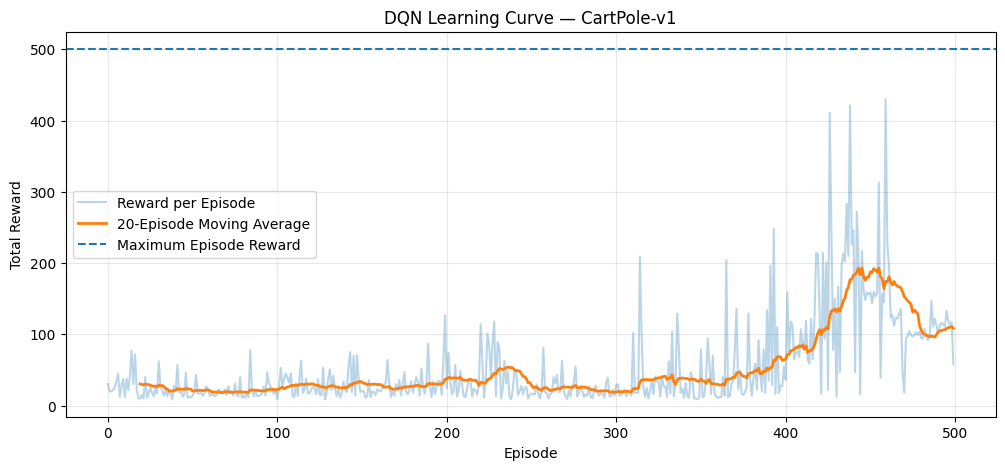

In [195]:
window = 20

reward_moving_avg = np.convolve(
    dqn_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(12, 5))

plt.plot(
    dqn_rewards,
    alpha=0.3,
    label="Reward per Episode"
)

plt.plot(
    np.arange(window - 1, len(dqn_rewards)),
    reward_moving_avg,
    label="20-Episode Moving Average",
    linewidth=2
)

plt.axhline(
    500,
    linestyle="--",
    label="Maximum Episode Reward"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("DQN Learning Curve — CartPole-v1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Learning Curve Analysis

Key Points:
- Episodes 1–200: The average reward hovers mostly between 20 and 40. The agent is still struggling to control the pole.
- Episodes 200–400: Progress is limited and fluctuates. The agent performs better at times, but performance remains unstable.
- Episodes 400–460: A significant jump occurs. The moving average reaches approximately 190, with some episodes achieving rewards exceeding 400.
- Episodes 460–500: The moving average declines, ending at around 110.

The dashed blue line at 500 represents the maximum possible reward per episode.

Has the agent learned?

Yes, there is evidence of learning, as some episodes reached over 400 steps (up from around 200). However, the agent fails to maintain high performance in the majority of episodes.

The decline toward the end could stem from fluctuations inherent in DQN training, shifting learning objectives, the contents of the replay buffer, or changes in network weights. It is not possible to pinpoint the exact cause of this drop based solely on the chart.

Conclusion: The agent has made progress, but we cannot yet claim that the training has reached stable convergence.

<h3> Step 12.2: Loss Chart

Now, we examine how the network's training error has changed.

Important note: A decrease in loss does not, by itself, guarantee that the agent has improved. Our primary metric remains the reward and the agent's performance within the environment.

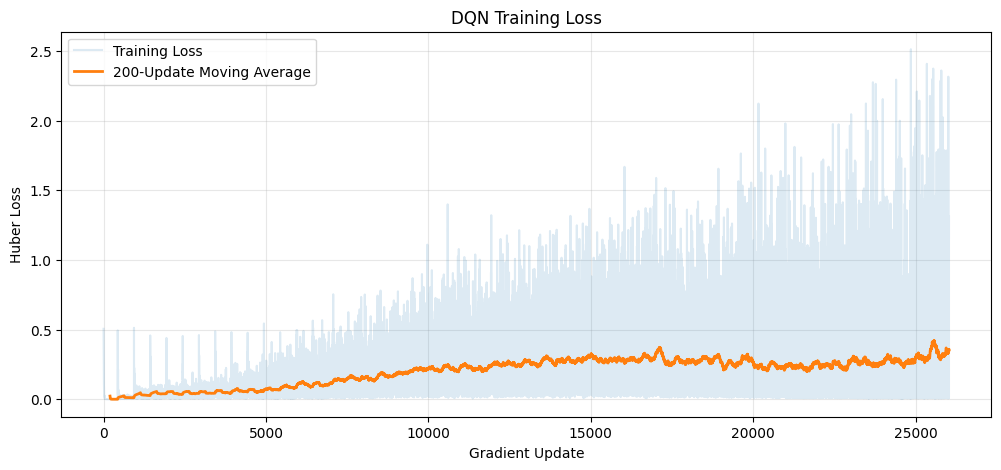

In [196]:
loss_window = 200

loss_moving_avg = np.convolve(
    dqn_losses,
    np.ones(loss_window) / loss_window,
    mode="valid"
)

plt.figure(figsize=(12, 5))

plt.plot(
    dqn_losses,
    alpha=0.15,
    label="Training Loss"
)

plt.plot(
    np.arange(loss_window - 1, len(dqn_losses)),
    loss_moving_avg,
    label="200-Update Moving Average",
    linewidth=2
)

plt.xlabel("Gradient Update")
plt.ylabel("Huber Loss")
plt.title("DQN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Analyzing the Training Loss Plot

DQN Training Loss — Huber Loss

Why has the loss increased?

In the plot, the moving average of the loss starts near zero and eventually reaches approximately 0.3. Furthermore, instantaneous loss values ​​occasionally exceed 2.0.
This does not necessarily indicate that the training process has failed.

In DQN, the learning target is not static:

$y=r+\gamma(1-d)\max_{a'}Q_{\text{target}}(s',a')$

As the network weights change, the target value also shifts. Additionally, the samples within the replay buffer evolve throughout the training process.
Therefore, unlike a typical supervised learning problem, we do not necessarily expect the loss to decrease monotonically.

What is concerning?

- The moving average of the loss shows an upward trend.
- Loss fluctuations have intensified toward the later stages of training.
- Concurrently, the reward plot shows a decline toward the end of training.

Taken together, these observations may indicate a degree of instability in the learning process; however, a definitive assessment requires evaluating the network's performance separately.

Note: The loss value alone is not a reliable metric for the success of a DQN. It is possible for the loss to increase while the policy improves; conversely, the loss could be low even if the agent performs poorly.

The plots indicate that the DQN is indeed learning, though it has not yet reached stable, near-optimal performance in the CartPole-v1 environment. Notably, the agent’s progress was impressive toward the later stages of training, but there is some decline in performance at the very end.

<h3> Step 13: DQN Evaluation

Now, we need to determine how well the trained network performs without any exploration. To do this, we run 100 episodes—keeping the network weights unchanged—and, at each step, select the action with the highest Q-value.

At this stage, there is no epsilon; the agent always selects the greedy action.

<h5> During evaluation, we use the final weights of the network we have trained; in the code we wrote, the weights do not change during the evaluation process.

In [197]:
def evaluate_dqn(
    env,
    policy_net,
    episodes=100,
    seed=1000
):
    rewards = []
    episode_lengths = []

    policy_net.eval()

    for episode in range(episodes):

        state, _ = env.reset(
            seed=seed + episode
        )

        total_reward = 0
        steps = 0

        while True:

            state_tensor = torch.as_tensor(
                state,
                dtype=torch.float32
            ).unsqueeze(0)

            with torch.no_grad():
                q_values = policy_net(state_tensor)
                action = q_values.argmax(
                    dim=1
                ).item()

            (
                next_state,
                reward,
                terminated,
                truncated,
                _
            ) = env.step(action)

            total_reward += reward
            steps += 1
            state = next_state

            if terminated or truncated:
                break

        rewards.append(total_reward)
        episode_lengths.append(steps)

    return (
        np.array(rewards),
        np.array(episode_lengths)
    )


eval_rewards, eval_steps = evaluate_dqn(
    env,
    policy_net,
    episodes=100
)

print("Evaluation episodes:", len(eval_rewards))
print("Mean reward:", eval_rewards.mean())
print("Median reward:", np.median(eval_rewards))
print("Maximum reward:", eval_rewards.max())
print("Minimum reward:", eval_rewards.min())
print(
    "Episodes reaching 500 steps:",
    np.sum(eval_rewards >= 500)
)

Evaluation episodes: 100
Mean reward: 109.16
Median reward: 108.5
Maximum reward: 120.0
Minimum reward: 101.0
Episodes reaching 500 steps: 0


- `policy_net.eval()` sets the network to evaluation mode; it does not modify the weights itself.
- `torch.no_grad()` disables gradient calculation.
- Within the evaluation function, `loss.backward()` and `optimizer.step()` are not executed; consequently, the weights are not updated.

The agent continues to interact with the environment and receive new states, but it relies solely on the trained network to select actions.
At this stage, `target_net` is also unnecessary, as only `policy_net` is used for action selection.

Three key observations regarding the outputs:

- The limited range of rewards—specifically 101 to 120—indicates that the performance of the greedy policy during this evaluation was relatively consistent, yet poor.
- In the training plot, some episodes reached over 400 steps; however, the final network did not even approach 500 steps during evaluation.
- This discrepancy suggests that strong performance in certain training episodes does not necessarily imply the acquisition of a robust and stable policy. Factors such as DQN fluctuations and exploration during training may contribute to this gap.

In CartPole-v1, the maximum possible reward per episode is 500. Therefore, we cannot yet claim to have solved the problem.

<h3> Step 14: Preparing a new experiment

#### So Important

In the next experiment, we will repeat the training from scratch for 1,500 episodes, while slowing down the Epsilon decay. This provides more opportunity for exploration and learning.

Additionally, it is advisable to perform a greedy evaluation every 100 episodes and save the best weights. This ensures that if the network's performance declines toward the end of training, we do not lose the best policy we have actually evaluated.
This experiment will help determine whether the core issue is a lack of experience or learning instability.

Now, we will improve the DQN training process to allow for more learning opportunities and to preserve the best version of the network, even if its performance declines later on.
This time, we are introducing three changes:
1. Increasing the training duration from 500 to 1,500 episodes.
2. Implementing a slower decay for Epsilon, using `epsilon_decay_steps=50000`.
3. Evaluating the model every 100 episodes and saving the weights of the best-performing policy.

Since we want to compare the result of the previous experiment with the new settings, we are starting the training from scratch.

In [198]:
# Fresh environments
train_env = gym.make("CartPole-v1")
eval_env = gym.make("CartPole-v1")

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
train_env.action_space.seed(42)

# Fresh networks
policy_net = DQN(
    state_dim,
    action_dim
)

target_net = copy.deepcopy(policy_net)
target_net.eval()

# Fresh optimizer and loss
optimizer = optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

loss_fn = nn.SmoothL1Loss()

# Fresh replay buffer
replay_buffer = ReplayBuffer(
    capacity=10_000
)

print("Fresh DQN experiment initialized.")
print("Replay buffer size:", len(replay_buffer))

Fresh DQN experiment initialized.
Replay buffer size: 0


<h3> Step 15: Training with periodic assessment

In this version, we evaluate the network every 100 episodes by running it for 10 episodes. If the average reward from this evaluation exceeds the best result obtained previously, we retain the weights from that version.

Why do we save the "best" weights?

Suppose that at Episode 600, the average evaluation score is 250, but by Episode 1200, it drops to 180. If we were to keep only the final weights, we might end up with a weaker policy.

By using this approach, we retain the weights that yielded the best evaluation result. 

Note, however, that since each evaluation step consists of only 10 episodes, this metric is somewhat stochastic; we will evaluate the best model more thoroughly later using a larger number of episodes.

In [199]:
def train_dqn_with_eval(
    train_env,
    eval_env,
    policy_net,
    target_net,
    replay_buffer,
    optimizer,
    episodes=1500,
    batch_size=64,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=50_000,
    target_update_freq=500,
    eval_interval=100,
    eval_episodes=10
):
    episode_rewards = []
    episode_steps = []
    loss_history = []
    eval_history = []

    total_steps = 0
    best_eval_reward = -np.inf
    best_policy_state = copy.deepcopy(
        policy_net.state_dict()
    )

    for episode in range(episodes):

        if episode == 0:
            state, _ = train_env.reset(seed=42)
        else:
            state, _ = train_env.reset()

        total_reward = 0
        steps = 0

        while True:

            epsilon = max(
                epsilon_end,
                epsilon_start
                - (epsilon_start - epsilon_end)
                * total_steps / epsilon_decay_steps
            )

            action = select_action(
                state,
                policy_net,
                epsilon,
                train_env
            )

            (
                next_state,
                reward,
                terminated,
                truncated,
                _
            ) = train_env.step(action)

            replay_buffer.push(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            total_reward += reward
            steps += 1
            total_steps += 1

            if len(replay_buffer) >= batch_size:

                loss = train_step(
                    replay_buffer,
                    policy_net,
                    target_net,
                    optimizer,
                    batch_size=batch_size,
                    gamma=gamma
                )

                if loss is not None:
                    loss_history.append(loss)

            if total_steps % target_update_freq == 0:
                target_net.load_state_dict(
                    policy_net.state_dict()
                )

            state = next_state

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(steps)

        # Periodic greedy evaluation
        if (episode + 1) % eval_interval == 0:

            eval_rewards, _ = evaluate_dqn(
                eval_env,
                policy_net,
                episodes=eval_episodes,
                seed=10_000
            )

            mean_eval_reward = float(
                np.mean(eval_rewards)
            )

            eval_history.append(
                (episode + 1, mean_eval_reward)
            )

            print(
                f"Episode {episode + 1:4d} | "
                f"Train reward (last 100): "
                f"{np.mean(episode_rewards[-100:]):.2f} | "
                f"Eval reward: {mean_eval_reward:.2f} | "
                f"Best eval: {max(best_eval_reward, mean_eval_reward):.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

            if mean_eval_reward > best_eval_reward:

                best_eval_reward = mean_eval_reward

                best_policy_state = copy.deepcopy(
                    policy_net.state_dict()
                )

            # Our network has no dropout or batch normalization,
            # but restore training mode explicitly.
            policy_net.train()

    # Restore the best evaluated policy
    policy_net.load_state_dict(best_policy_state)

    target_net.load_state_dict(
        policy_net.state_dict()
    )
    target_net.eval()

    torch.save(
        best_policy_state,
        "dqn_cartpole_best.pth"
    )

    return (
        np.array(episode_rewards),
        np.array(episode_steps),
        np.array(loss_history),
        eval_history,
        best_eval_reward
    )

<h3> Step 16: Train Execution

This experiment will be longer than the previous run.
Note: In this implementation, evaluation uses a separate environment; therefore, evaluation episodes are not added to the training replay buffer.

In [200]:
(
    dqn_rewards,
    dqn_steps,
    dqn_losses,
    dqn_eval_history,
    best_eval_reward
) = train_dqn_with_eval(
    train_env=train_env,
    eval_env=eval_env,
    policy_net=policy_net,
    target_net=target_net,
    replay_buffer=replay_buffer,
    optimizer=optimizer,
    episodes=1500,
    batch_size=64,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=50_000,
    target_update_freq=500,
    eval_interval=100,
    eval_episodes=10
)

print("\nBest evaluation reward:", best_eval_reward)
print("Training episodes:", len(dqn_rewards))
print("Gradient updates:", len(dqn_losses))

Episode  100 | Train reward (last 100): 21.98 | Eval reward: 122.30 | Best eval: 122.30 | Epsilon: 0.958
Episode  200 | Train reward (last 100): 24.80 | Eval reward: 98.90 | Best eval: 122.30 | Epsilon: 0.911
Episode  300 | Train reward (last 100): 24.62 | Eval reward: 81.50 | Best eval: 122.30 | Epsilon: 0.864
Episode  400 | Train reward (last 100): 22.66 | Eval reward: 88.70 | Best eval: 122.30 | Epsilon: 0.821
Episode  500 | Train reward (last 100): 23.31 | Eval reward: 96.20 | Best eval: 122.30 | Epsilon: 0.777
Episode  600 | Train reward (last 100): 22.16 | Eval reward: 72.90 | Best eval: 122.30 | Epsilon: 0.735
Episode  700 | Train reward (last 100): 21.05 | Eval reward: 119.30 | Best eval: 122.30 | Epsilon: 0.695
Episode  800 | Train reward (last 100): 26.59 | Eval reward: 148.80 | Best eval: 148.80 | Epsilon: 0.644
Episode  900 | Train reward (last 100): 28.43 | Eval reward: 94.10 | Best eval: 148.80 | Epsilon: 0.590
Episode 1000 | Train reward (last 100): 25.21 | Eval reward: 

The results of this experiment show significant improvement compared to the 500-episode run; however, an important point has also emerged: while our DQN has managed to learn a relatively strong policy, the learning process is unstable, and we have not yet reached the threshold for solving the CartPole problem.

The evaluation trend reveals the following:
- Episodes 100 to 600: Performance ranges from approximately 73 to 122; learning remains weak and unstable.
- Episodes 700 to 1200: The overall trend improves, with the average evaluation reaching 197.2.
- Episode 1300: The best result—341.4—is recorded, indicating the acquisition of a stronger policy.
- Episodes 1400 and 1500: Performance drops to 72.6 and 67.5, respectively.

This final decline is significant; the network weights have shifted as training continued, resulting in a weaker policy by the end of the training process.

The current `policy_net` should contain the weights from the best checkpoint evaluated at Episode 1300, rather than the inferior weights from Episode 1500.

The file `dqn_cartpole_best.pth` has also been saved to store these same weights.

Why is the training reward significantly lower than the evaluation reward?

This discrepancy can be explained:
- During training, the agent selected a random action with a probability of 0.37.
- During evaluation, the agent always chose the action with the highest Q-value.
- In the CartPole environment, even a few random actions can cause the pole to fall.

Nevertheless, the difference is quite large; therefore, we should evaluate the performance of the saved checkpoint on an independent set of episodes.

<h3> Step 17: Plotting the Evaluation Chart

This plot is more important than the training reward plot, as it shows how the policy—without exploration—evolved during the learning process.

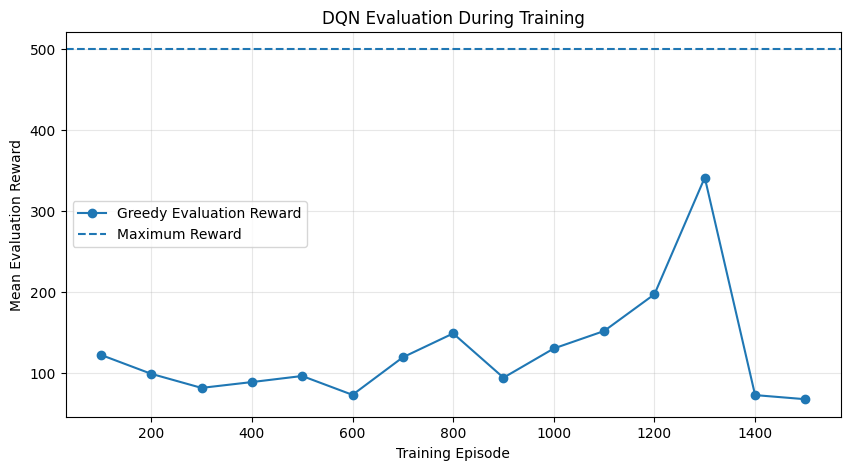

In [201]:
eval_episodes_x = [
    item[0] for item in dqn_eval_history
]

eval_rewards_y = [
    item[1] for item in dqn_eval_history
]

plt.figure(figsize=(10, 5))

plt.plot(
    eval_episodes_x,
    eval_rewards_y,
    marker="o",
    label="Greedy Evaluation Reward"
)

plt.axhline(
    500,
    linestyle="--",
    label="Maximum Reward"
)

plt.xlabel("Training Episode")
plt.ylabel("Mean Evaluation Reward")
plt.title("DQN Evaluation During Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<h3> Step 18: Independent evaluation of the best model

In this experiment, the weights remain unchanged, and we use new seeds to obtain a more independent evaluation.

If the average reward remains high, we have strong evidence that the selected checkpoint has indeed learned an appropriate policy. If performance drops significantly, we need to further investigate the training configuration and the stability of the DQN.

In [202]:
final_eval_rewards, final_eval_steps = evaluate_dqn(
    eval_env,
    policy_net,
    episodes=100,
    seed=20_000
)

print("Evaluation episodes:", len(final_eval_rewards))
print("Mean reward:", final_eval_rewards.mean())
print("Median reward:", np.median(final_eval_rewards))
print("Standard deviation:", final_eval_rewards.std())
print("Minimum reward:", final_eval_rewards.min())
print("Maximum reward:", final_eval_rewards.max())

print(
    "Episodes reaching 500 steps:",
    np.sum(final_eval_rewards >= 500)
)

print(
    "Episodes reaching at least 475 steps:",
    np.sum(final_eval_rewards >= 475)
)

Evaluation episodes: 100
Mean reward: 300.29
Median reward: 256.0
Standard deviation: 117.14711221366065
Minimum reward: 153.0
Maximum reward: 500.0
Episodes reaching 500 steps: 18
Episodes reaching at least 475 steps: 22


Three key findings:
- The average score of 300.29 is significantly better than the 109.16 average of the previous model.
- The discrepancy between the mean and the median indicates that the average has been skewed upward by a few highly successful episodes; the model's performance is not yet consistent.
- The standard benchmark for solving CartPole-v1 is an average score of at least 475 over 100 evaluation episodes. Our model has not yet reached this threshold.

<h3> Step 19: Longer DQN Training

In the previous training run, at episode 1500, the Epsilon value was still 0.272—meaning it had not yet reached the minimum threshold of 0.05. Therefore, we have the opportunity to continue the training, allowing the agent to learn for a longer duration with reduced exploration.

This time, we will increase the number of episodes to 3,000 and conduct periodic evaluations over 20 episodes. We will keep the other parameters constant to better assess the impact of extending the training duration.

<h3> Step 19.1: Creating a New Experiment

For a fair comparison, we run this experiment from scratch, without using the weights or memory from the previous experiment.

In [203]:
# Reproducibility
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)

train_env.action_space.seed(123)

# Fresh networks
policy_net = DQN(
    state_dim,
    action_dim
)

target_net = copy.deepcopy(policy_net)
target_net.eval()

# Fresh optimizer
optimizer = optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

loss_fn = nn.SmoothL1Loss()

# Fresh replay buffer
replay_buffer = ReplayBuffer(
    capacity=10_000
)

print("Fresh experiment initialized.")
print("Replay buffer size:", len(replay_buffer))

Fresh experiment initialized.
Replay buffer size: 0


<h3> Step 19.2: Implementation of a 3,000-episode training program

We use the `train_dqn_with_eval` function that we created earlier.

This experiment takes more time. The best weights are still stored based on the average of periodic evaluations.

In [204]:
(
    dqn_rewards,
    dqn_steps,
    dqn_losses,
    dqn_eval_history,
    best_eval_reward
) = train_dqn_with_eval(
    train_env=train_env,
    eval_env=eval_env,
    policy_net=policy_net,
    target_net=target_net,
    replay_buffer=replay_buffer,
    optimizer=optimizer,
    episodes=3000,
    batch_size=64,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay_steps=50_000,
    target_update_freq=500,
    eval_interval=100,
    eval_episodes=20
)

print("\nBest evaluation reward:", best_eval_reward)
print("Training episodes:", len(dqn_rewards))
print("Gradient updates:", len(dqn_losses))

Episode  100 | Train reward (last 100): 23.65 | Eval reward: 153.85 | Best eval: 153.85 | Epsilon: 0.955
Episode  200 | Train reward (last 100): 23.37 | Eval reward: 261.15 | Best eval: 261.15 | Epsilon: 0.911
Episode  300 | Train reward (last 100): 25.05 | Eval reward: 80.40 | Best eval: 261.15 | Epsilon: 0.863
Episode  400 | Train reward (last 100): 24.34 | Eval reward: 68.65 | Best eval: 261.15 | Epsilon: 0.817
Episode  500 | Train reward (last 100): 23.27 | Eval reward: 60.35 | Best eval: 261.15 | Epsilon: 0.773
Episode  600 | Train reward (last 100): 20.00 | Eval reward: 76.35 | Best eval: 261.15 | Epsilon: 0.735
Episode  700 | Train reward (last 100): 22.66 | Eval reward: 96.35 | Best eval: 261.15 | Epsilon: 0.692
Episode  800 | Train reward (last 100): 29.33 | Eval reward: 97.70 | Best eval: 261.15 | Epsilon: 0.636
Episode  900 | Train reward (last 100): 27.08 | Eval reward: 95.25 | Best eval: 261.15 | Epsilon: 0.584
Episode 1000 | Train reward (last 100): 20.54 | Eval reward: 1

Our DQN model has finally achieved excellent performance; however, before we can claim to have solved CartPole, we need to independently evaluate the best-performing model. :)))))))

What has happened?

- Up to episode 1700: The training reward remains relatively low, and the agent is learning gradually.
- From episode 1800 onwards: As Epsilon reaches 0.05, the average training reward begins to improve.
- Episode 2700: The average evaluation score reaches 489.95; this indicates that the model's performance during this evaluation is very close to the environment's upper limit.
- Episodes 2800 to 3000: Evaluation results decline again. This demonstrates that DQN training remains unstable.

It is important to note that our function saved the best weights and reloaded them at the end. Therefore, the current `policy_net` model corresponds to the checkpoint from episode 2700, rather than the weights from the final episode.

We still need to conduct one final test.
The standard criterion for solving CartPole-v1 is an average reward of at least 475 over 100 evaluation episodes. Our result of 489.95 is based on 20 periodic evaluation episodes, rather than 100 independent ones.

Furthermore, since we evaluated multiple checkpoints using the same set of seeds and selected the best one, the result from this best evaluation might be slightly optimistic.

<h3> Step 20: Final Evaluation of the Best Model

This evaluation does not alter the network weights; it merely measures the performance of the policy.

If the average reward in this test is at least 475, we can conclude that the model has met the standard benchmark for solving CartPole.

In [205]:
final_eval_rewards, final_eval_steps = evaluate_dqn(
    eval_env,
    policy_net,
    episodes=100,
    seed=20_000
)

print("Evaluation episodes:", len(final_eval_rewards))
print("Mean reward:", final_eval_rewards.mean())
print("Median reward:", np.median(final_eval_rewards))
print("Standard deviation:", final_eval_rewards.std())
print("Minimum reward:", final_eval_rewards.min())
print("Maximum reward:", final_eval_rewards.max())

print(
    "Episodes reaching 500 steps:",
    np.sum(final_eval_rewards >= 500)
)

print(
    "Episodes reaching at least 475 steps:",
    np.sum(final_eval_rewards >= 475)
)

Evaluation episodes: 100
Mean reward: 459.65
Median reward: 500.0
Standard deviation: 121.26247358519453
Minimum reward: 62.0
Maximum reward: 500.0
Episodes reaching 500 steps: 90
Episodes reaching at least 475 steps: 90


The DQN model managed to achieve the maximum reward in the environment in 90% of the episodes. However, there is an important point: the model's performance is not yet stable across all episodes.

Point 1: The model's performance is very good.

In 90 out of 100 episodes, the agent reached the 500-step limit. This indicates that the model has learned an effective policy for controlling the CartPole.

Point 2: Why is the average still low?

The standard criterion for solving CartPole-v1 is achieving an average score of at least 475 over 100 consecutive episodes. Our average is 459.65; therefore, we have not yet met this threshold.
Since 90 episodes achieved a score of exactly 500, the average for the remaining 10 episodes was only 96.5. Thus, the primary issue is not the model's typical performance, but rather a few instances of significant failure.

The high standard deviation of 121.26 further reflects this instability.

Before we change the architecture, it is best to examine the distribution of rewards to see how those 10 poor-performing episodes failed.

In [206]:
print("Lowest 10 episode rewards:")
print(np.sort(final_eval_rewards)[:10])

print("\nReward distribution:")
print("500 reward:", np.sum(final_eval_rewards == 500))
print("475–499:", np.sum(
    (final_eval_rewards >= 475) &
    (final_eval_rewards < 500)
))
print("Below 475:", np.sum(final_eval_rewards < 475))

Lowest 10 episode rewards:
[ 62.  72.  74.  80.  98. 105. 110. 111. 114. 139.]

Reward distribution:
500 reward: 90
475–499: 0
Below 475: 10


This output shows exactly where the model’s problem lies: the DQN performs excellently most of the time, but fails catastrophically in a small number of episodes.

The distribution of rewards falls into two completely distinct groups:
- Group 1: 90 episodes with a full reward of 500.
- Group 2: 10 episodes with a reward ranging between 62 and 139.

Therefore, the core issue is not merely that the agent typically fails around the 450th step; rather, under certain conditions, it loses control of the pole much earlier.

This pattern may indicate that the learned policy is sensitive to specific initial states. To confirm this, however, we would need to examine the trajectories of the unsuccessful episodes.

<h3> Step 21: Save current DQN results

Our DQN model yielded the following results during independent evaluation:
- Average reward: 459.65
- Number of episodes with a reward of 500: 90 / 100
- Standard deviation: 121.26

We will use these results as a baseline; the library-based model must be evaluated on the same `CartPole-v1` environment using an identical set of seeds.

For a fair comparison, it is best to define the training budget based on the total number of interaction steps with the environment—rather than simply the number of episodes—since episode lengths can vary. Furthermore, we will precisely document the library's default settings to ensure that any observed differences are correctly attributed to the algorithm itself rather than the configuration.

In [209]:
# Create results directory
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the best model weights
torch.save(
    policy_net.state_dict(),
    results_dir / "custom_dqn_best.pth"
)

# 2. Save numerical arrays
np.savez_compressed(
    results_dir / "custom_dqn_arrays.npz",

    training_rewards=dqn_rewards,
    training_steps=dqn_steps,
    training_losses=dqn_losses,

    evaluation_history=np.asarray(
        dqn_eval_history,
        dtype=np.float64
    ),

    independent_eval_rewards=final_eval_rewards,
    independent_eval_steps=final_eval_steps
)

# 3. Save experiment configuration and metrics
metrics = {
    "algorithm": "Custom DQN",
    "environment": "CartPole-v1",

    "training": {
        "episodes": 3000,
        "learning_rate": 0.001,
        "gamma": 0.99,
        "batch_size": 64,
        "replay_buffer_capacity": 10000,
        "epsilon_start": 1.0,
        "epsilon_end": 0.05,
        "epsilon_decay_steps": 50000,
        "target_update_frequency": 500,
        "evaluation_interval": 100,
        "evaluation_episodes": 20,
        "gradient_updates": len(dqn_losses)
    },

    "best_periodic_evaluation_reward": float(
        best_eval_reward
    ),

    "independent_evaluation": {
        "episodes": len(final_eval_rewards),
        "mean_reward": float(
            np.mean(final_eval_rewards)
        ),
        "median_reward": float(
            np.median(final_eval_rewards)
        ),
        "std_reward": float(
            np.std(final_eval_rewards)
        ),
        "min_reward": float(
            np.min(final_eval_rewards)
        ),
        "max_reward": float(
            np.max(final_eval_rewards)
        ),
        "episodes_reaching_500": int(
            np.sum(final_eval_rewards >= 500)
        ),
        "episodes_reaching_475": int(
            np.sum(final_eval_rewards >= 475)
        )
    }
}

with open(
    results_dir / "custom_dqn_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metrics,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Baseline saved successfully.")

for file in sorted(results_dir.iterdir()):
    print(file.name)

Baseline saved successfully.
custom_dqn_arrays.npz
custom_dqn_best.pth
custom_dqn_metrics.json
